# Notebook 5: Model Comparison and Backtesting

This notebook demonstrates how to compare Vasicek and HJM interest rate models through backtesting, analyzing their performance on held-out data, and generating recommendations for different use cases.

## Learning Objectives

- Split historical data into train/test sets for proper model validation
- Backtest calibrated models against held-out data
- Compare models using error metrics (MAE, RMSE, MAPE, hit ratio)
- Generate model recommendations for different use cases
- Visualize comparison results

In [1]:
# Standard imports
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project imports
from src.data.loader import load_interest_rate_data
from src.analysis.pca import compute_pca
from src.models.vasicek import VasicekModel
from src.models.hjm import HJMModel
from src.validation import (
    backtest_model,
    compare_models,
    get_model_recommendation,
)
from src.visualization.simulation_plots import (
    plot_model_comparison,
    plot_backtest_results,
)

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# Seed for reproducibility
np.random.seed(42)

## 1. Load and Split Data

We'll load the sample treasury rates data and split it into training (80%) and test (20%) sets.

In [2]:
# Load the full dataset
data_path = Path("../data/sample_treasury_rates.csv")
full_dataset = load_interest_rate_data(data_path)

print(f"Dataset loaded: {full_dataset.source_name}")
print(f"Date range: {full_dataset.date_range[0]} to {full_dataset.date_range[1]}")
print(f"Observations: {full_dataset.n_observations}")
print(f"Maturities: {full_dataset.maturities}")

2026-01-20 22:17:40 | INFO     | hjm_vasicek.data.loader | Loading interest rate data from ../data/sample_treasury_rates.csv
2026-01-20 22:17:40 | INFO     | hjm_vasicek.data.loader | Loaded 252 observations with 7 maturities from sample_treasury_rates
Dataset loaded: sample_treasury_rates
Date range: 2024-01-02 to 2024-12-18
Observations: 252
Maturities: [ 0.25  0.5   1.    2.    5.   10.   30.  ]


In [3]:
# Split data into train (80%) and test (20%)
n_obs = full_dataset.n_observations
split_idx = int(n_obs * 0.8)

# Get split date
train_end_date = full_dataset.observation_dates[split_idx - 1]
test_start_date = full_dataset.observation_dates[split_idx]

# Create train and test datasets
train_data = full_dataset.filter_dates(end_date=train_end_date)
test_data = full_dataset.filter_dates(start_date=test_start_date)

print(f"\nTraining data:")
print(f"  Period: {train_data.date_range[0]} to {train_data.date_range[1]}")
print(f"  Observations: {train_data.n_observations} ({train_data.n_observations/n_obs:.1%})")

print(f"\nTest data:")
print(f"  Period: {test_data.date_range[0]} to {test_data.date_range[1]}")
print(f"  Observations: {test_data.n_observations} ({test_data.n_observations/n_obs:.1%})")

2026-01-20 22:17:40 | INFO     | hjm_vasicek.data.loader | Filtered dataset from 2024-01-02 to 2024-10-08: 201 observations
2026-01-20 22:17:40 | INFO     | hjm_vasicek.data.loader | Filtered dataset from 2024-10-09 to 2024-12-18: 51 observations

Training data:
  Period: 2024-01-02 to 2024-10-08
  Observations: 201 (79.8%)

Test data:
  Period: 2024-10-09 to 2024-12-18
  Observations: 51 (20.2%)


## 2. Calibrate Models on Training Data

We calibrate both the Vasicek and HJM models using only the training data.

In [4]:
# Calibrate Vasicek model
vasicek_model = VasicekModel()
vasicek_model.calibrate(train_data)

print("Vasicek Model Calibration Results")
print("=" * 40)
params = vasicek_model.get_parameters()
for name, value in params.items():
    print(f"  {name}: {value:.6f}")

print("\nParameter Interpretations:")
for name, interp in vasicek_model.get_parameter_interpretations().items():
    print(f"  {interp}")

2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.vasicek | Calibrating Vasicek to 201 observations from 2024-01-02 to 2024-10-08
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.vasicek | MLE calibration converged: kappa=7.1032, theta=0.054115, sigma=0.007286, LL=1259.78
Vasicek Model Calibration Results
  kappa: 7.103229
  theta: 0.054115
  sigma: 0.007286

Parameter Interpretations:
  Mean reversion speed: κ = 7.1032/year. The interest rate reverts halfway to its long-term mean in approximately 0.10 years.
  Long-term mean rate: θ = 5.4115%. This is the equilibrium level to which interest rates tend to revert over time.
  Volatility: σ = 0.7286%/√year. This produces a long-run standard deviation of approximately 0.1933% around the mean.


In [5]:
# Perform PCA on training data for HJM model
pca_result = compute_pca(train_data, n_components=3)

print("PCA Results for HJM Model")
print("=" * 40)
print(f"Explained variance by component:")
for i, (ratio, interp) in enumerate(zip(pca_result.explained_variance_ratio, pca_result.interpretations)):
    print(f"  PC{i+1} ({interp}): {ratio:.1%}")
print(f"\nTotal explained variance: {sum(pca_result.explained_variance_ratio[:3]):.1%}")

2026-01-20 22:17:40 | INFO     | hjm_vasicek.analysis.pca | Computing PCA on changes with n_components=3
2026-01-20 22:17:40 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 201 observations
2026-01-20 22:17:40 | INFO     | hjm_vasicek.analysis.pca | Computed 200 yield curve changes
2026-01-20 22:17:40 | INFO     | hjm_vasicek.analysis.pca | PCA complete: 3 components explain 88.49% of variance
PCA Results for HJM Model
Explained variance by component:
  PC1 (PC1: Level (parallel shift) - uniform impact across maturities): 61.6%
  PC2 (PC2: Slope (tilt) - steepening of yield curve): 18.4%
  PC3 (PC3: Curvature (inverse butterfly) - belly vs wings movement): 8.5%

Total explained variance: 88.5%


In [6]:
# Calibrate HJM model using PCA results
hjm_model = HJMModel(pca_result=pca_result, n_factors=3)
hjm_model.calibrate()

print("HJM Model Calibration Results")
print("=" * 40)
for name, interp in hjm_model.get_parameter_interpretations().items():
    print(f"  {interp}")

2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Initialized HJM model with 3 factors from PCA (3 components)
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Calibrating HJM model with 3 factors
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | HJM calibration complete: 3 factors, maturities=[0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 30.0]
HJM Model Calibration Results
  Number of factors: 3. The HJM model uses 3 PCA components to model yield curve movements.
  PC1: Level (parallel shift) - uniform impact across maturities: Explains 61.6% of yield curve variance. Daily volatility magnitude: 0.1009%.
  PC2: Slope (tilt) - steepening of yield curve: Explains 18.4% of yield curve variance. Daily volatility magnitude: 0.0551%.
  PC3: Curvature (inverse butterfly) - belly vs wings movement: Explains 8.5% of yield curve variance. Daily volatility magnitude: 0.0374%.
  Total variance explained: 88.5%. The 3-factor model captures this fraction of yield curve movements.


## 3. Backtest Individual Models

We test each model's predictive performance on the held-out test data.

In [7]:
# Backtest Vasicek model
vasicek_result = backtest_model(
    model=vasicek_model,
    validation_data=test_data,
    prediction_horizon=1,
)

print(vasicek_result.summary())

2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.backtesting | Backtesting VasicekModel model with 51 observations, horizon=1
2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.backtesting | Backtest complete: MAE=0.000395, RMSE=0.000514, Hit Ratio=60.00%
Validation Results for VASICEK Model
Validation Period: 2024-10-09 to 2024-12-18
Number of Observations: 50

Error Metrics:
  MAE:  0.000395 (3.95 basis points)
  RMSE: 0.000514 (5.14 basis points)
  MAPE: 0.72%
  Hit Ratio: 60.0%

Quality Rating: EXCELLENT


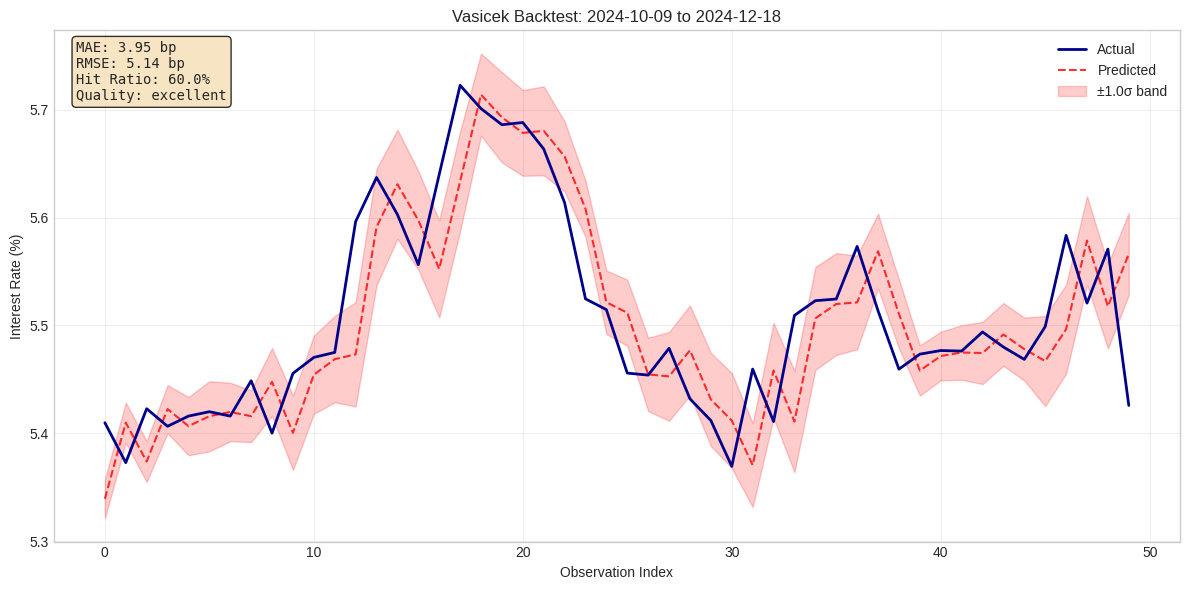

In [8]:
# Plot Vasicek backtest results
fig = plot_backtest_results(vasicek_result)
plt.show()

In [9]:
# Backtest HJM model
hjm_result = backtest_model(
    model=hjm_model,
    validation_data=test_data,
    prediction_horizon=1,
)

print(hjm_result.summary())

2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.backtesting | Backtesting HJMModel model with 51 observations, horizon=1
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 100 paths, horizon=0.00 years, dt=0.003968
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulation complete: 100 paths, terminal mean curve: [0.0534, ..., 0.0460]
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 100 paths, horizon=0.00 years, dt=0.003968
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulation complete: 100 paths, terminal mean curve: [0.0541, ..., 0.0471]
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 100 paths, horizon=0.00 years, dt=0.003968
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulation complete: 100 paths, terminal mean curve: [0.0537, ..., 0.0477]
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 100 paths, horizon=0.00 years, dt=0.003968
2026

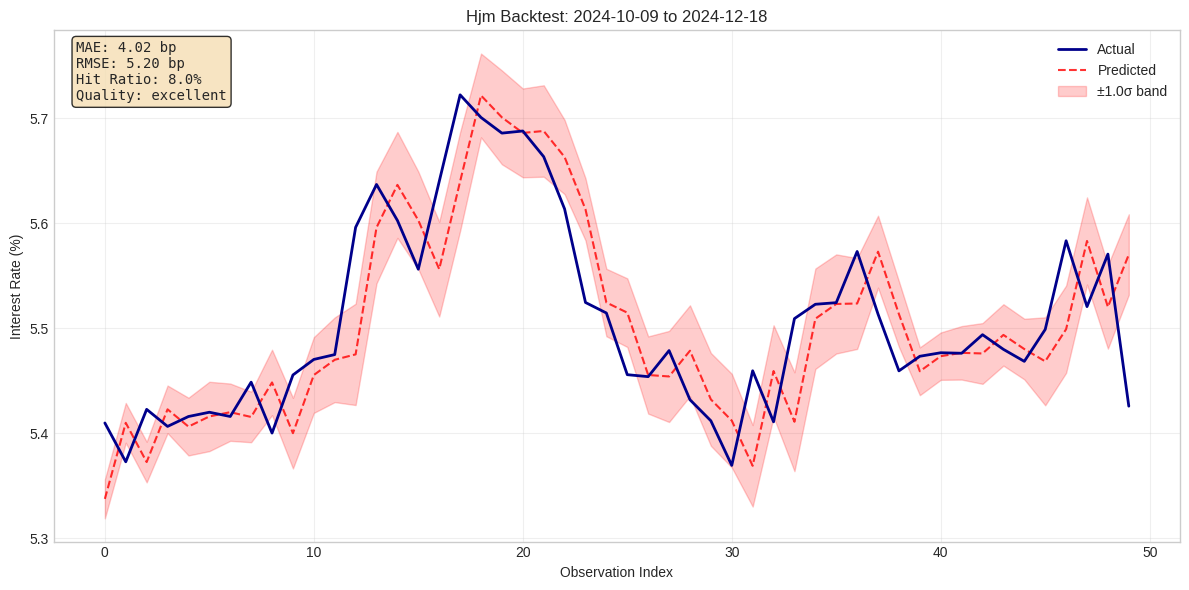

In [10]:
# Plot HJM backtest results
fig = plot_backtest_results(hjm_result)
plt.show()

## 4. Compare Models Side-by-Side

Now we compare both models to determine which performs better for different use cases.

In [11]:
# Run comprehensive model comparison
comparison = compare_models(
    models=[vasicek_model, hjm_model],
    validation_data=test_data,
    model_names=["Vasicek", "HJM (3-factor)"],
)

# Print comparison summary
print(comparison.summary())

2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.comparison | Comparing 2 models: ['Vasicek', 'HJM (3-factor)']
2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.comparison | Backtesting model: Vasicek
2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.backtesting | Backtesting VasicekModel model with 51 observations, horizon=1
2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.backtesting | Backtest complete: MAE=0.000395, RMSE=0.000514, Hit Ratio=60.00%
2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.comparison | Backtesting model: HJM (3-factor)
2026-01-20 22:17:40 | INFO     | hjm_vasicek.validation.backtesting | Backtesting HJMModel model with 51 observations, horizon=1
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 100 paths, horizon=0.00 years, dt=0.003968
2026-01-20 22:17:40 | INFO     | hjm_vasicek.models.hjm | Simulation complete: 100 paths, terminal mean curve: [0.0534, ..., 0.0460]
2026-01-20 22:17:40 | INFO     | hj

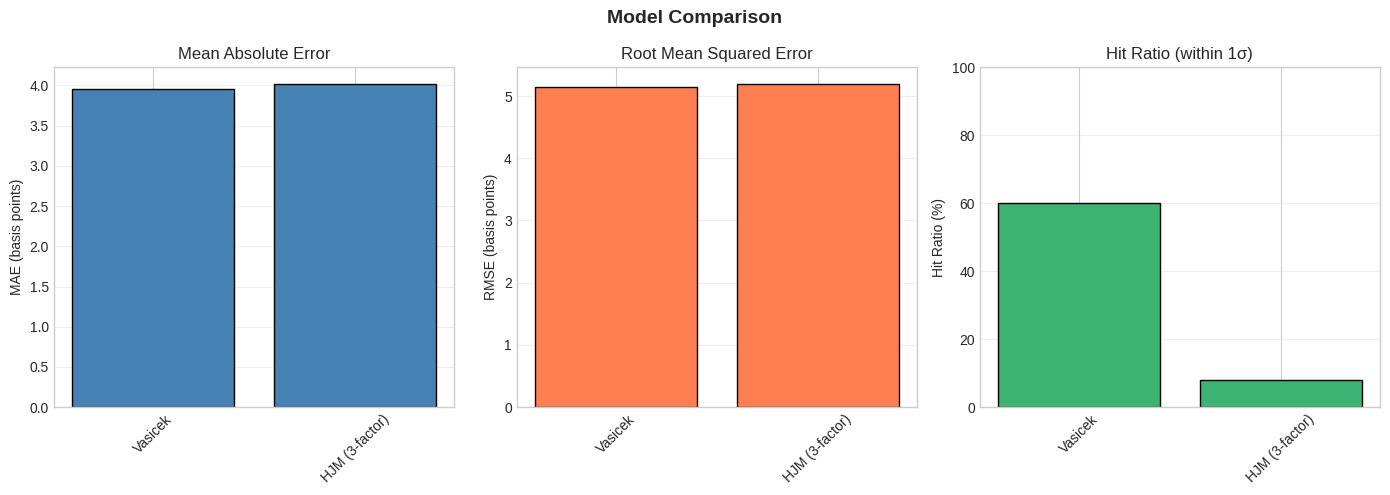

In [12]:
# Visualize model comparison
fig = plot_model_comparison(comparison)
plt.show()

## 5. Get Model Recommendations

Based on the comparison results, we get recommendations for different use cases.

In [13]:
# Get recommendations for different use cases
use_cases = ["short_rate", "yield_curve", "derivatives", "general"]

for use_case in use_cases:
    recommendation = get_model_recommendation(comparison, use_case)
    print(recommendation)
    print("\n" + "-" * 60 + "\n")

Recommendation for Short Rate:
  Model: Vasicek

Justification:
  - Best Mean Absolute Error: 3.95 basis points
  - Short rate predictions prioritize point accuracy
  - Quality rating: excellent

------------------------------------------------------------

Recommendation for Yield Curve:
  Model: HJM (3-factor)

Justification:
  - Full yield curve modeling requires curve dynamics
  - HJM captures multiple factors (level, slope, curvature)
  - RMSE: 5.20 basis points
  - Quality rating: excellent

------------------------------------------------------------

Recommendation for Derivatives:
  Model: Vasicek

Justification:
  - Derivatives pricing needs consistent rate distribution coverage
  - Best Hit Ratio: 60.0%
  - Higher hit ratio = more reliable probability estimates
  - Quality rating: excellent

------------------------------------------------------------

Recommendation for General:
  Model: Vasicek

Justification:
  - General purpose modeling balances accuracy and robustness
 

## 6. Detailed Error Analysis

Let's analyze the prediction errors in more detail.

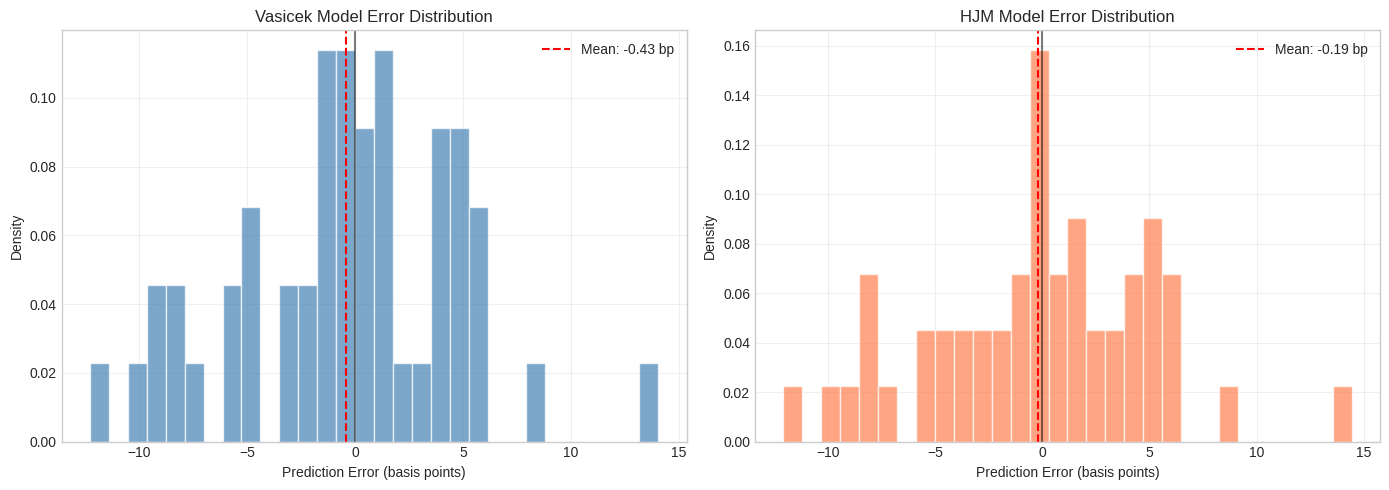


Error Statistics (in basis points)
Metric               Vasicek         HJM            
--------------------------------------------------
Mean Error           -0.43           -0.19          
Std Error            5.12            5.20           
Min Error            -12.29          -12.10         
Max Error            14.04           14.44          


In [14]:
# Compute error distributions
vasicek_errors = (vasicek_result.predicted_values - vasicek_result.actual_values) * 10000  # in basis points
hjm_errors = (hjm_result.predicted_values - hjm_result.actual_values) * 10000  # in basis points

# Plot error distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Vasicek errors
axes[0].hist(vasicek_errors, bins=30, density=True, alpha=0.7, color='steelblue', edgecolor='white')
axes[0].axvline(np.mean(vasicek_errors), color='red', linestyle='--', label=f'Mean: {np.mean(vasicek_errors):.2f} bp')
axes[0].axvline(0, color='black', linestyle='-', alpha=0.5)
axes[0].set_xlabel('Prediction Error (basis points)')
axes[0].set_ylabel('Density')
axes[0].set_title('Vasicek Model Error Distribution')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# HJM errors
axes[1].hist(hjm_errors, bins=30, density=True, alpha=0.7, color='coral', edgecolor='white')
axes[1].axvline(np.mean(hjm_errors), color='red', linestyle='--', label=f'Mean: {np.mean(hjm_errors):.2f} bp')
axes[1].axvline(0, color='black', linestyle='-', alpha=0.5)
axes[1].set_xlabel('Prediction Error (basis points)')
axes[1].set_ylabel('Density')
axes[1].set_title('HJM Model Error Distribution')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print error statistics
print("\nError Statistics (in basis points)")
print("=" * 50)
print(f"{'Metric':<20} {'Vasicek':<15} {'HJM':<15}")
print("-" * 50)
print(f"{'Mean Error':<20} {np.mean(vasicek_errors):<15.2f} {np.mean(hjm_errors):<15.2f}")
print(f"{'Std Error':<20} {np.std(vasicek_errors):<15.2f} {np.std(hjm_errors):<15.2f}")
print(f"{'Min Error':<20} {np.min(vasicek_errors):<15.2f} {np.min(hjm_errors):<15.2f}")
print(f"{'Max Error':<20} {np.max(vasicek_errors):<15.2f} {np.max(hjm_errors):<15.2f}")

## 7. Time Series of Prediction Errors

Visualize how prediction errors evolve over the test period.

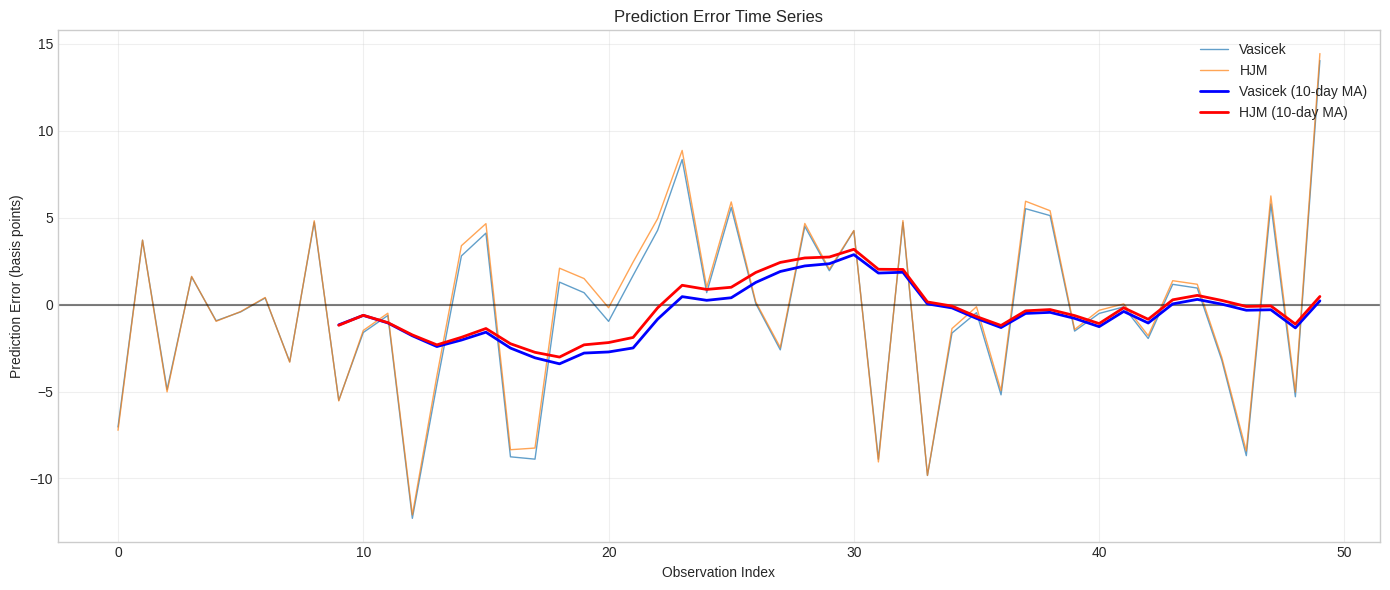

In [15]:
# Plot error time series
fig, ax = plt.subplots(figsize=(14, 6))

n_obs = len(vasicek_errors)
x = np.arange(n_obs)

ax.plot(x, vasicek_errors, label='Vasicek', alpha=0.7, linewidth=1)
ax.plot(x, hjm_errors, label='HJM', alpha=0.7, linewidth=1)
ax.axhline(0, color='black', linestyle='-', alpha=0.5)

# Add rolling mean
window = 10
vasicek_rolling = np.convolve(vasicek_errors, np.ones(window)/window, mode='valid')
hjm_rolling = np.convolve(hjm_errors, np.ones(window)/window, mode='valid')

ax.plot(x[window-1:], vasicek_rolling, label='Vasicek (10-day MA)', linewidth=2, color='blue')
ax.plot(x[window-1:], hjm_rolling, label='HJM (10-day MA)', linewidth=2, color='red')

ax.set_xlabel('Observation Index')
ax.set_ylabel('Prediction Error (basis points)')
ax.set_title('Prediction Error Time Series')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Summary and Conclusions

Let's summarize the key findings from our model comparison.

In [16]:
# Final summary
print("="*60)
print("MODEL COMPARISON SUMMARY")
print("="*60)

print(f"\nTest Period: {test_data.date_range[0]} to {test_data.date_range[1]}")
print(f"Number of Test Observations: {test_data.n_observations}")

print("\n" + comparison.get_metrics_table())

print("\n" + "="*60)
print("KEY TAKEAWAYS")
print("="*60)

# Determine overall winner
v_mae = vasicek_result.mae
h_mae = hjm_result.mae

if v_mae < h_mae:
    print("\n- Vasicek model has better point prediction accuracy (lower MAE)")
    print("- Suitable for short-term rate forecasting applications")
else:
    print("\n- HJM model has better point prediction accuracy (lower MAE)")
    print("- Multi-factor approach captures rate dynamics effectively")

print("\n- Use Vasicek for simple short-rate modeling with interpretable parameters")
print("- Use HJM for full yield curve modeling and derivatives pricing")
print("- Both models can be improved with longer calibration periods or regime detection")

MODEL COMPARISON SUMMARY

Test Period: 2024-10-09 to 2024-12-18
Number of Test Observations: 51

Model Comparison Metrics
Model           MAE (bp)     RMSE (bp)    Hit Ratio    Quality   
----------------------------------------------------------------------
Vasicek         3.95         5.14         60.0        % excellent 
HJM (3-factor)  4.02         5.20         8.0         % excellent 
----------------------------------------------------------------------

Best Model by Metric:
  MAE: Vasicek
  RMSE: Vasicek
  HIT_RATIO: Vasicek

KEY TAKEAWAYS

- Vasicek model has better point prediction accuracy (lower MAE)
- Suitable for short-term rate forecasting applications

- Use Vasicek for simple short-rate modeling with interpretable parameters
- Use HJM for full yield curve modeling and derivatives pricing
- Both models can be improved with longer calibration periods or regime detection


## Next Steps

After comparing these models, you might want to:

1. **Extend the analysis** with different prediction horizons (5-day, 10-day, 30-day)
2. **Test robustness** by using different train/test split ratios
3. **Explore regime changes** by splitting data by market conditions
4. **Combine models** using ensemble methods for potentially better predictions
5. **Export results** for reporting using the export module